# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 02 – Comparación de los subconjuntos C-MAPSS

## Objetivo

En este notebook se analizarán los subconjuntos **FD002, FD003 y FD004** y se compararán con **FD001**, estudiado previamente en profundidad.

El objetivo no es repetir todo el análisis exploratorio realizado sobre FD001, sino identificar las principales diferencias entre los cuatro escenarios de C-MAPSS y determinar qué papel puede tener cada uno dentro del proyecto de mantenimiento predictivo.

Los cuatro subconjuntos presentan diferentes combinaciones de condiciones operativas y modos de fallo:

| Dataset | Motores train | Motores test | Condiciones operativas | Modos de fallo |
|---|---:|---:|---:|---|
| FD001 | 100 | 100 | 1 | 1 (HPC) |
| FD002 | 260 | 259 | 6 | 1 (HPC) |
| FD003 | 100 | 100 | 1 | 2 (HPC + Fan) |
| FD004 | 249 | 248 | 6 | 2 (HPC + Fan) |

Se prestará especial atención a:
- Las diferencias en el número y longitud de las trayectorias.
- El efecto de las distintas condiciones operativas.
- La variabilidad y evolución de los sensores.
- Las diferencias respecto al comportamiento observado en FD001.
- La presencia de múltiples modos de fallo en FD003 y FD004.
- La utilidad potencial de cada subconjunto para detección de degradación, clasificación y estimación de RUL.

Este análisis permitirá contextualizar las diferencias entre los cuatro subconjuntos y establecer una base para el desarrollo inicial de los modelos sobre FD001 y su posterior extensión y evaluación en escenarios con diferentes condiciones operativas y mecanismos de degradación.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para la carga, manipulación, análisis y visualización de los datos. Se utilizan las mismas herramientas empleadas en el análisis inicial de FD001.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Comprensión del dataset C-MAPSS de los 4 subconjuntos

### 1.1. Carga de los datos

En primer lugar, se cargarán los conjuntos de entrenamiento **FD001, FD002, FD003 y FD004**.

Todos ellos presentan la misma estructura de 26 variables:

- Identificador del motor (`unit`).
- Número de ciclo (`cycle`).
- 3 variables correspondientes a las condiciones operativas (`op_setting_1`, `op_setting_2`, `op_setting_3`).
- 21 mediciones de sensores (`sensor_1` – `sensor_21`).

La carga conjunta permitirá comparar posteriormente las características de los cuatro escenarios.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"

In [ ]:
columns = (
    ["unit", "cycle"] +
    [f"op_setting_{i}" for i in range(1, 4)] +
    [f"sensor_{i}" for i in range(1, 22)]
)

In [ ]:
df_FD001 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

df_FD002 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD002.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

df_FD003 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD003.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

df_FD004 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD004.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

Una vez cargados los cuatro subconjuntos, se agrupan los DataFrames en un diccionario para facilitar su análisis conjunto. A continuación, se realiza una primera comparación de sus dimensiones, considerando el número total de observaciones, el número de motores y el número de variables.

In [ ]:
datasets = {
    "FD001": df_FD001,
    "FD002": df_FD002,
    "FD003": df_FD003,
    "FD004": df_FD004
}

for nombre, df in datasets.items():
    print(f"{nombre}")
    print(f"Observaciones: {len(df)}")
    print(f"Motores: {df['unit'].nunique()}")
    print(f"Variables: {df.shape[1]}")
    print()

FD001
Observaciones: 20631
Motores: 100
Variables: 26

FD002
Observaciones: 53759
Motores: 260
Variables: 26

FD003
Observaciones: 24720
Motores: 100
Variables: 26

FD004
Observaciones: 61249
Motores: 249
Variables: 26



Los cuatro subconjuntos mantienen la misma estructura de **26 variables**, formada por el identificador del motor, el ciclo, 3 condiciones operativas y 21 sensores.

Sin embargo, presentan diferencias importantes en su tamaño. FD001 y FD003 contienen 100 motores, mientras que FD002 y FD004 incluyen un número mayor de unidades y observaciones.

FD003 presenta más observaciones que FD001 pese a contener el mismo número de motores, lo que indica que las trayectorias presentan, en conjunto, una mayor longitud. Estas diferencias se analizarán posteriormente mediante la distribución del número de ciclos por motor.

Por tanto, aunque los cuatro subconjuntos tienen la misma estructura de variables, difieren en el número de motores y en la longitud de sus series temporales.

Una vez verificadas las dimensiones de los cuatro subconjuntos, se realiza una comprobación adicional de su integridad.

Se analiza la presencia de valores ausentes y registros duplicados por identificador de motor y ciclo. También se comprueba que las trayectorias comiencen en el ciclo 1 y presenten una numeración consecutiva, sin ciclos intermedios ausentes.

Estas verificaciones permiten identificar posibles irregularidades en la estructura temporal antes de realizar los análisis posteriores.

In [ ]:
for nombre, df in datasets.items():

    # Valores ausentes
    nulos = df.isnull().sum().sum()

    # Registros duplicados por motor y ciclo
    duplicados = df.duplicated(
        subset=["unit", "cycle"]
    ).sum()

    # Comprobación de continuidad de los ciclos
    ciclos = df.groupby("unit")["cycle"].agg(
        ["min", "max", "count", "nunique"]
    )

    trayectorias_validas = (
        (ciclos["min"] == 1)
        & (ciclos["max"] == ciclos["count"])
        & (ciclos["count"] == ciclos["nunique"])
    )

    print(nombre)
    print("Valores nulos:", nulos)
    print("Duplicados motor-ciclo:", duplicados)
    print(
        "Trayectorias consecutivas:",
        trayectorias_validas.sum(),
        "de",
        len(ciclos)
    )
    print()

FD001
Valores nulos: 0
Duplicados motor-ciclo: 0
Trayectorias consecutivas: 100 de 100

FD002
Valores nulos: 0
Duplicados motor-ciclo: 0
Trayectorias consecutivas: 260 de 260

FD003
Valores nulos: 0
Duplicados motor-ciclo: 0
Trayectorias consecutivas: 100 de 100

FD004
Valores nulos: 0
Duplicados motor-ciclo: 0
Trayectorias consecutivas: 249 de 249



Las comprobaciones de integridad realizadas sobre los cuatro subconjuntos confirman que no existen valores ausentes ni registros duplicados para una misma combinación de motor y ciclo.

Asimismo, se ha verificado que todas las trayectorias comienzan en el ciclo 1 y presentan una numeración consecutiva, sin ciclos intermedios ausentes. Esta condición se cumple en los 100 motores de FD001, los 260 de FD002, los 100 de FD003 y los 249 de FD004.

Por tanto, no es necesario realizar tratamientos adicionales de valores ausentes, duplicados o discontinuidades temporales antes de continuar con el análisis exploratorio.

### 1.2. Comparación de la duración de las trayectorias

Una vez comparado el tamaño de los cuatro subconjuntos, se analiza la duración de las trayectorias de cada motor. Para ello, se obtiene el último ciclo registrado de cada unidad, que en los conjuntos de entrenamiento corresponde a la longitud de su serie temporal.

In [ ]:
ciclos_por_motor = {}

for nombre, df in datasets.items():
    ciclos = df.groupby("unit")["cycle"].max()
    ciclos_por_motor[nombre] = ciclos

    print(f"{nombre}")
    print(ciclos.describe())
    print()

FD001
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

FD002
count    260.000000
mean     206.765385
std       46.782198
min      128.000000
25%      174.000000
50%      199.000000
75%      230.250000
max      378.000000
Name: cycle, dtype: float64

FD003
count    100.00000
mean     247.20000
std       86.48384
min      145.00000
25%      189.75000
50%      220.50000
75%      279.75000
max      525.00000
Name: cycle, dtype: float64

FD004
count    249.00000
mean     245.97992
std       73.11080
min      128.00000
25%      190.00000
50%      234.00000
75%      290.00000
max      543.00000
Name: cycle, dtype: float64



La duración de las series temporales varía entre los cuatro subconjuntos.

FD001 y FD002 presentan distribuciones muy similares, con una duración media de aproximadamente **206 ciclos** y una mediana de **199 ciclos**. Esto indica que, aunque FD002 incorpora múltiples condiciones operativas, las longitudes de las trayectorias son globalmente similares a las observadas en FD001.

Por otro lado, FD003 y FD004 presentan trayectorias generalmente más largas. Sus duraciones medias son aproximadamente **247 y 246 ciclos**, respectivamente, y algunos motores alcanzan los **525 ciclos en FD003** y los **543 ciclos en FD004**.

Además, FD003 y FD004 presentan una mayor dispersión en la duración de las trayectorias, especialmente FD003.

Por tanto, los subconjuntos asociados a dos modos de degradación presentan en estos datos trayectorias más largas y heterogéneas que FD001 y FD002. No obstante, estas diferencias descriptivas no permiten atribuir directamente la mayor duración a la existencia de múltiples modos de fallo.

### 1.3. Análisis inicial de las condiciones operativas

Los subconjuntos C-MAPSS presentan diferentes condiciones de funcionamiento del motor. Para realizar una primera comparación entre ellos, se analizará la variabilidad de las tres variables operativas (`op_setting_1`, `op_setting_2` y `op_setting_3`) mediante el número de valores únicos que presenta cada una.

In [ ]:
for nombre, df in datasets.items():
    print(f"{nombre}")

    for col in ["op_setting_1", "op_setting_2", "op_setting_3"]:
        print(f"{col}: {df[col].nunique()} valores únicos")

    print()

FD001
op_setting_1: 158 valores únicos
op_setting_2: 13 valores únicos
op_setting_3: 1 valores únicos

FD002
op_setting_1: 536 valores únicos
op_setting_2: 105 valores únicos
op_setting_3: 2 valores únicos

FD003
op_setting_1: 160 valores únicos
op_setting_2: 14 valores únicos
op_setting_3: 1 valores únicos

FD004
op_setting_1: 536 valores únicos
op_setting_2: 105 valores únicos
op_setting_3: 2 valores únicos



El número de valores únicos de las variables `op_setting` no coincide directamente con el número de condiciones operativas definido para cada subconjunto. Esto se debe a que estas variables no representan una etiqueta discreta de la condición de funcionamiento, sino valores asociados a los parámetros operativos del motor, que presentan pequeñas variaciones.

FD001 y FD003 muestran un comportamiento muy similar en sus variables operativas, coherente con el hecho de que ambos corresponden a un escenario con una única condición operativa.

Por otro lado, FD002 y FD004 presentan una variabilidad considerablemente mayor en `op_setting_1` y `op_setting_2`, mientras que `op_setting_3` toma dos valores diferentes. Este comportamiento es coherente con la existencia de seis condiciones operativas en estos subconjuntos.

Por tanto, en FD002 y FD004 será especialmente importante considerar el efecto de las condiciones operativas al analizar los sensores, ya que una variación en una señal puede estar relacionada tanto con un cambio en el régimen de funcionamiento como con el proceso de degradación.

### 1.4. Análisis de FD002

FD002 introduce una mayor complejidad respecto a FD001 debido a la presencia de seis condiciones operativas diferentes. En este apartado se analizará cómo se manifiestan estas condiciones en los datos y qué efecto pueden tener sobre el comportamiento de los sensores.

#### 1.4.1. Identificación visual de las condiciones operativas en FD002

Para analizar cómo se distribuyen las condiciones operativas en FD002, se representarán conjuntamente `op_setting_1` y `op_setting_2`. Esta visualización permitirá comprobar si los valores observados se agrupan en diferentes regímenes de funcionamiento.

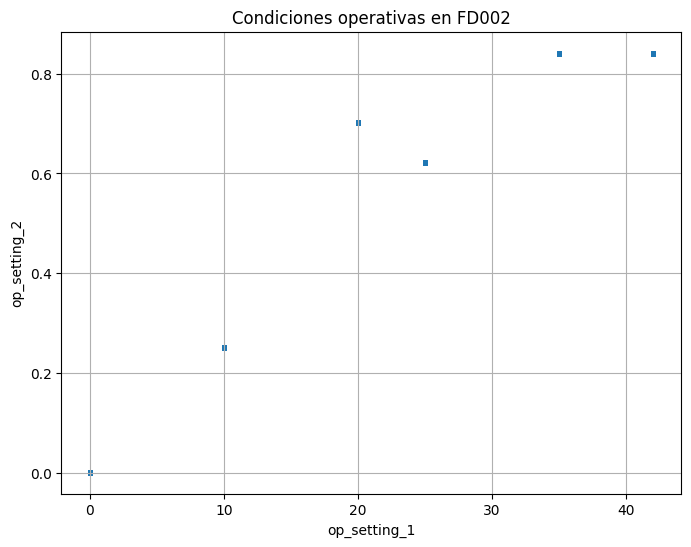

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_FD002["op_setting_1"],
    df_FD002["op_setting_2"],
    s=5,
    alpha=0.3
)

plt.xlabel("op_setting_1")
plt.ylabel("op_setting_2")
plt.title("Condiciones operativas en FD002")
plt.grid(True)
plt.show()

La representación conjunta de `op_setting_1` y `op_setting_2` permite observar **seis grupos claramente diferenciados**, correspondientes a las seis condiciones operativas presentes en FD002.

Aunque ambas variables presentan un elevado número de valores únicos, estos valores se concentran alrededor de seis combinaciones principales. Las pequeñas diferencias dentro de cada grupo corresponden a variaciones de los parámetros operativos, mientras que la separación entre los grupos permite distinguir los diferentes regímenes de funcionamiento.

Este resultado confirma directamente en los datos la existencia de múltiples condiciones operativas en FD002.

La presencia de diferentes regímenes deberá tenerse en cuenta posteriormente al analizar la evolución de los sensores, ya que un cambio en sus valores puede deberse tanto al proceso de degradación como a un cambio en las condiciones de funcionamiento.

#### 1.4.2. Efecto de las condiciones operativas sobre los sensores

Una vez identificados los diferentes regímenes operativos de FD002, se analizará cómo esta variabilidad puede reflejarse en las mediciones de los sensores. Para ello, se estudiará inicialmente la evolución temporal del `sensor_2` para un motor concreto.

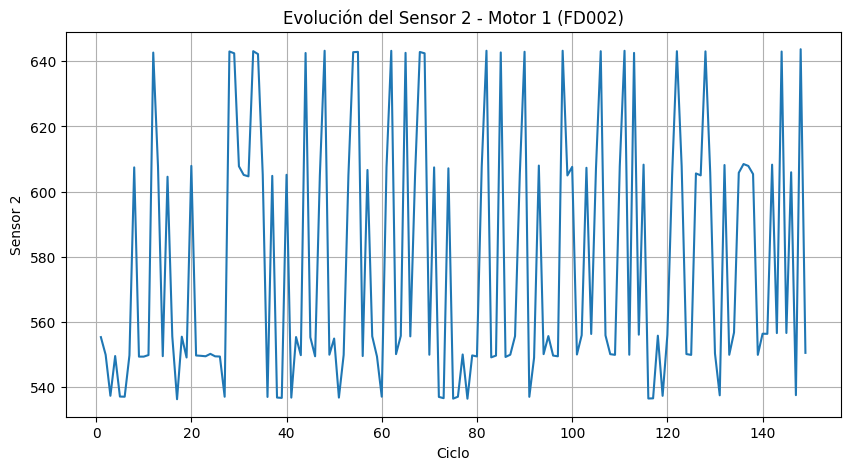

In [ ]:
motor_1_FD002 = df_FD002[df_FD002["unit"] == 1]

plt.figure(figsize=(10, 5))

plt.plot(
    motor_1_FD002["cycle"],
    motor_1_FD002["sensor_2"]
)

plt.xlabel("Ciclo")
plt.ylabel("Sensor 2")
plt.title("Evolución del Sensor 2 - Motor 1 (FD002)")
plt.grid(True)
plt.show()

Al representar la evolución del `sensor_2` para un motor de FD002 se observa un comportamiento muy diferente al encontrado previamente en FD001.

La señal presenta numerosos cambios bruscos entre diferentes niveles a lo largo de los ciclos, dificultando la identificación visual de una tendencia de degradación. Estos cambios pueden estar relacionados con las distintas condiciones operativas bajo las que funciona el motor.

Por tanto, en FD002 no resulta adecuado interpretar directamente la evolución temporal de un sensor sin considerar simultáneamente el régimen operativo. Parte de la variabilidad observada puede deberse a cambios en las condiciones de funcionamiento y no necesariamente al deterioro del motor.

Esto introduce una dificultad adicional respecto a FD001: será necesario distinguir posteriormente entre la variabilidad provocada por las condiciones operativas y la asociada al proceso de degradación.

#### 1.4.3. Relación entre las condiciones operativas y los sensores

Para comprobar la relación entre las condiciones operativas y el comportamiento de los sensores, se analizará conjuntamente `op_setting_1` y `sensor_2` en FD002. De esta forma, se podrá observar si los distintos regímenes de funcionamiento están asociados a diferentes niveles de la señal del sensor.

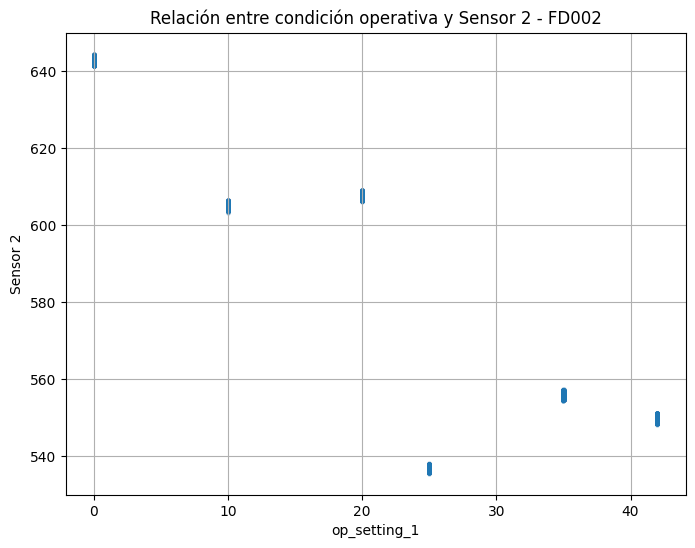

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_FD002["op_setting_1"],
    df_FD002["sensor_2"],
    s=5,
    alpha=0.3
)

plt.xlabel("op_setting_1")
plt.ylabel("Sensor 2")
plt.title("Relación entre condición operativa y Sensor 2 - FD002")
plt.grid(True)
plt.show()

La representación del `sensor_2` respecto a `op_setting_1` muestra seis agrupaciones diferenciadas, asociadas a distintos niveles de la señal del sensor. Esto indica que las mediciones del `sensor_2` presentan una relación con las condiciones operativas del motor.

Este resultado respalda la hipótesis planteada en el apartado anterior: parte de los cambios bruscos observados durante la evolución temporal del sensor podrían estar relacionados con variaciones en las condiciones de funcionamiento. No obstante, esta representación global no permite determinar qué cambios concretos de la trayectoria de un motor se deben a cada régimen operativo.

Por tanto, en los subconjuntos con múltiples condiciones operativas, como FD002 y FD004, es necesario considerar tanto el régimen de funcionamiento como la evolución de la degradación al interpretar las mediciones de los sensores.

Esta característica deberá tenerse en cuenta posteriormente durante el preprocesamiento y el modelado, para evitar interpretar como degradación variaciones asociadas a cambios en las condiciones operativas.

### 1.5. Análisis de FD003

FD003 mantiene una única condición operativa, al igual que FD001, pero introduce **dos modos de degradación asociados al HPC (High Pressure Compressor) y al Fan**.

Por tanto, este subconjunto resulta especialmente interesante para estudiar cómo cambia el comportamiento de las señales cuando existen diferentes mecanismos de degradación.

Además, se analizará si la información proporcionada por C-MAPSS permite identificar el modo de fallo correspondiente a cada motor, ya que esta información sería necesaria para plantear una clasificación supervisada de tipos de fallo.

#### 1.5.1. Información disponible sobre el tipo de fallo

En primer lugar, se comprobará la estructura de `train_FD003.txt` para determinar si el conjunto de datos incluye alguna variable que identifique explícitamente el modo de degradación asociado a cada motor.

In [ ]:
print(df_FD003.columns.tolist())
print(df_FD003.head())

['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
   unit  cycle  op_setting_1  op_setting_2  op_setting_3  sensor_1  sensor_2  \
0     1      1       -0.0005        0.0004         100.0    518.67    642.36   
1     1      2        0.0008       -0.0003         100.0    518.67    642.50   
2     1      3       -0.0014       -0.0002         100.0    518.67    642.18   
3     1      4       -0.0020        0.0001         100.0    518.67    642.92   
4     1      5        0.0016        0.0000         100.0    518.67    641.68   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1583.23   1396.84     14.62  ...     522.31    2388.01    8145.32   
1   1584.69   1396.89     14.62  ...     52

El archivo `train_FD003.txt` mantiene la misma estructura que FD001: identificador del motor, ciclo, tres variables operativas y 21 sensores.

Aunque la documentación de C-MAPSS indica que FD003 contiene dos modos de degradación (HPC y Fan), el archivo de entrenamiento no incorpora una variable que identifique explícitamente el modo de fallo correspondiente a cada observación o motor.

Por tanto, la presencia de dos modos de fallo en el escenario no implica directamente que se disponga de las etiquetas necesarias para realizar una clasificación supervisada HPC/Fan.

#### 1.5.2. Implicaciones para la clasificación de fallos

La ausencia de etiquetas que identifiquen el mecanismo de degradación de cada motor supone una limitación para el desarrollo de modelos de clasificación supervisada de tipos de fallo.

Aunque FD003 contempla dos mecanismos de degradación, asociados al HPC y al Fan, esta información describe las características generales del escenario y no proporciona directamente una categoría de fallo para cada trayectoria. Además, no se dispone de información suficiente en el archivo para determinar si estos mecanismos afectan de forma exclusiva o simultánea a los motores.

Por tanto, no sería metodológicamente adecuado asignar etiquetas HPC o Fan a partir de los patrones observados en los sensores sin disponer de una referencia externa que permita comprobar su correspondencia con los mecanismos reales de degradación.

No obstante, FD003 sigue siendo útil para evaluar modelos de detección de anomalías y prognosis de RUL en un escenario que incorpora diferentes mecanismos de degradación. La posibilidad de abordar la clasificación de tipos de fallo dependerá de la disponibilidad de etiquetas adicionales o de un planteamiento alternativo cuya interpretación y limitaciones estén justificadas.

#### 1.5.3. Cálculo de la RUL en FD003

Para estudiar la evolución de los sensores conforme los motores se aproximan al final de vida, se calculará la **Remaining Useful Life (RUL)** de cada observación.

Al igual que en FD001, las trayectorias del conjunto de entrenamiento alcanzan el final de vida, por lo que la RUL puede calcularse como la diferencia entre el último ciclo de cada motor y el ciclo actual:

**RUL = ciclo final del motor − ciclo actual**

Esto permitirá comparar las trayectorias de diferentes motores utilizando como referencia su distancia al final de vida.

In [ ]:
df_FD003["RUL"] = (
    df_FD003.groupby("unit")["cycle"].transform("max")
    - df_FD003["cycle"]
)

df_FD003[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,258
1,1,2,257
2,1,3,256
3,1,4,255
4,1,5,254


In [ ]:
df_FD003[["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
24715,100,148,4
24716,100,149,3
24717,100,150,2
24718,100,151,1
24719,100,152,0


La variable `RUL` se ha calculado correctamente para cada observación. Para cada motor, su valor disminuye en una unidad por ciclo hasta alcanzar **RUL = 0 en el último ciclo de su trayectoria**.

Por ejemplo, el motor 1 comienza con una RUL de 258 ciclos, mientras que el motor 100 finaliza en el ciclo 152 con RUL = 0.

A partir de esta variable será posible comparar la evolución de los sensores de diferentes motores utilizando como referencia su distancia al final de vida, independientemente de la duración total de cada trayectoria.

#### 1.5.4. Seleccionar los cinco motores representativos de FD003

Debido a que las trayectorias de FD003 presentan diferentes duraciones, se seleccionarán cinco motores representativos de su distribución. Al igual que en FD001, se tomarán como referencia el mínimo, el primer cuartil (Q1), la mediana, el tercer cuartil (Q3) y el máximo.

In [ ]:
ciclos_FD003 = ciclos_por_motor["FD003"]

valores_objetivo = {
    "Mínimo": ciclos_FD003.min(),
    "Q1": ciclos_FD003.quantile(0.25),
    "Mediana": ciclos_FD003.median(),
    "Q3": ciclos_FD003.quantile(0.75),
    "Máximo": ciclos_FD003.max()
}

motores_representativos_FD003 = {}

for nombre, valor in valores_objetivo.items():
    motor = (ciclos_FD003 - valor).abs().idxmin()
    motores_representativos_FD003[nombre] = motor

    print(
        f"{nombre}: Motor {motor} - "
        f"{ciclos_FD003.loc[motor]} ciclos"
    )

Mínimo: Motor 99 - 145 ciclos
Q1: Motor 51 - 190 ciclos
Mediana: Motor 21 - 220 ciclos
Q3: Motor 6 - 278 ciclos
Máximo: Motor 55 - 525 ciclos


Se han seleccionado cinco motores representativos de FD003 según la duración de sus trayectorias: mínimo, primer cuartil (Q1), mediana, tercer cuartil (Q3) y máximo.

Esta selección permite analizar motores con diferentes longitudes de vida sin escoger las unidades de forma arbitraria. Las trayectorias seleccionadas varían desde los **145 ciclos del motor 99** hasta los **525 ciclos del motor 55**.

A continuación, se utilizarán estos motores para estudiar si los patrones de degradación observados en los sensores son consistentes entre diferentes trayectorias o si FD003 presenta una mayor heterogeneidad respecto a FD001.

##### 1.5.4.1. Análisis de la evolución de los sensores respecto a la RUL

Una vez seleccionados los cinco motores representativos, se analizará la evolución de varios sensores respecto a la RUL. Esto permitirá comparar las trayectorias utilizando como referencia la distancia al final de vida y estudiar si existen diferencias en los patrones de degradación entre los motores de FD003.

In [ ]:
sensores_analisis = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_15"
]

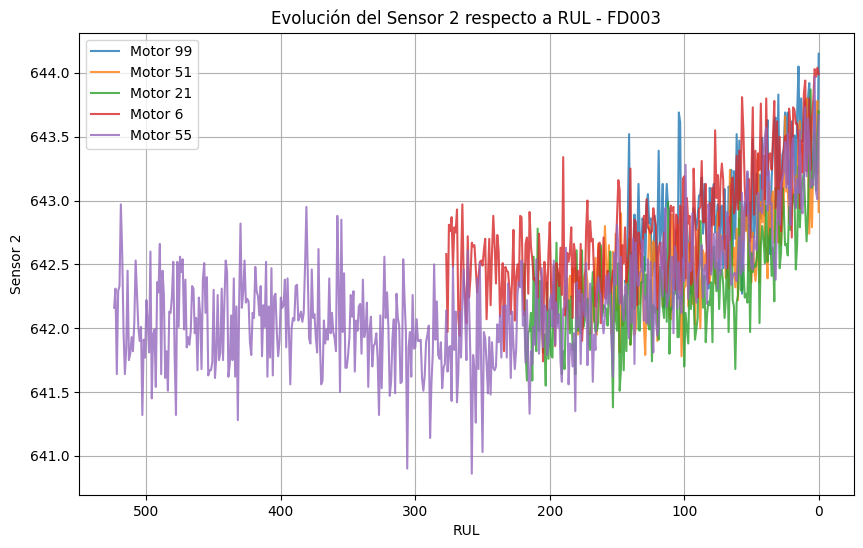

In [ ]:
# Sensor 2
motores_FD003 = list(motores_representativos_FD003.values())

plt.figure(figsize=(10, 6))

for motor in motores_FD003:
    datos_motor = df_FD003[df_FD003["unit"] == motor]

    plt.plot(
        datos_motor["RUL"],
        datos_motor["sensor_2"],
        label=f"Motor {motor}",
        alpha=0.8
    )

plt.xlabel("RUL")
plt.ylabel("Sensor 2")
plt.title("Evolución del Sensor 2 respecto a RUL - FD003")
plt.legend()
plt.grid(True)

# RUL alta a la izquierda y final de vida a la derecha
plt.gca().invert_xaxis()

plt.show()

La evolución del `sensor_2` respecto a la RUL muestra un comportamiento general similar entre los cinco motores seleccionados. A medida que disminuye la vida útil restante y los motores se aproximan al final de vida, el valor del sensor tiende a aumentar.

Las principales diferencias se encuentran en la longitud de las trayectorias y en el momento a partir del cual comienza a apreciarse de forma más clara la evolución asociada a la degradación. El motor 55, cuya trayectoria alcanza los 525 ciclos, presenta un periodo inicial prolongado con valores relativamente estables antes de mostrar una tendencia ascendente.

No se observan grupos claramente diferenciados entre los motores a partir de este sensor. Por tanto, esta representación no permite identificar los dos modos de degradación presentes en FD003 ni asociar las trayectorias a un tipo de fallo concreto.

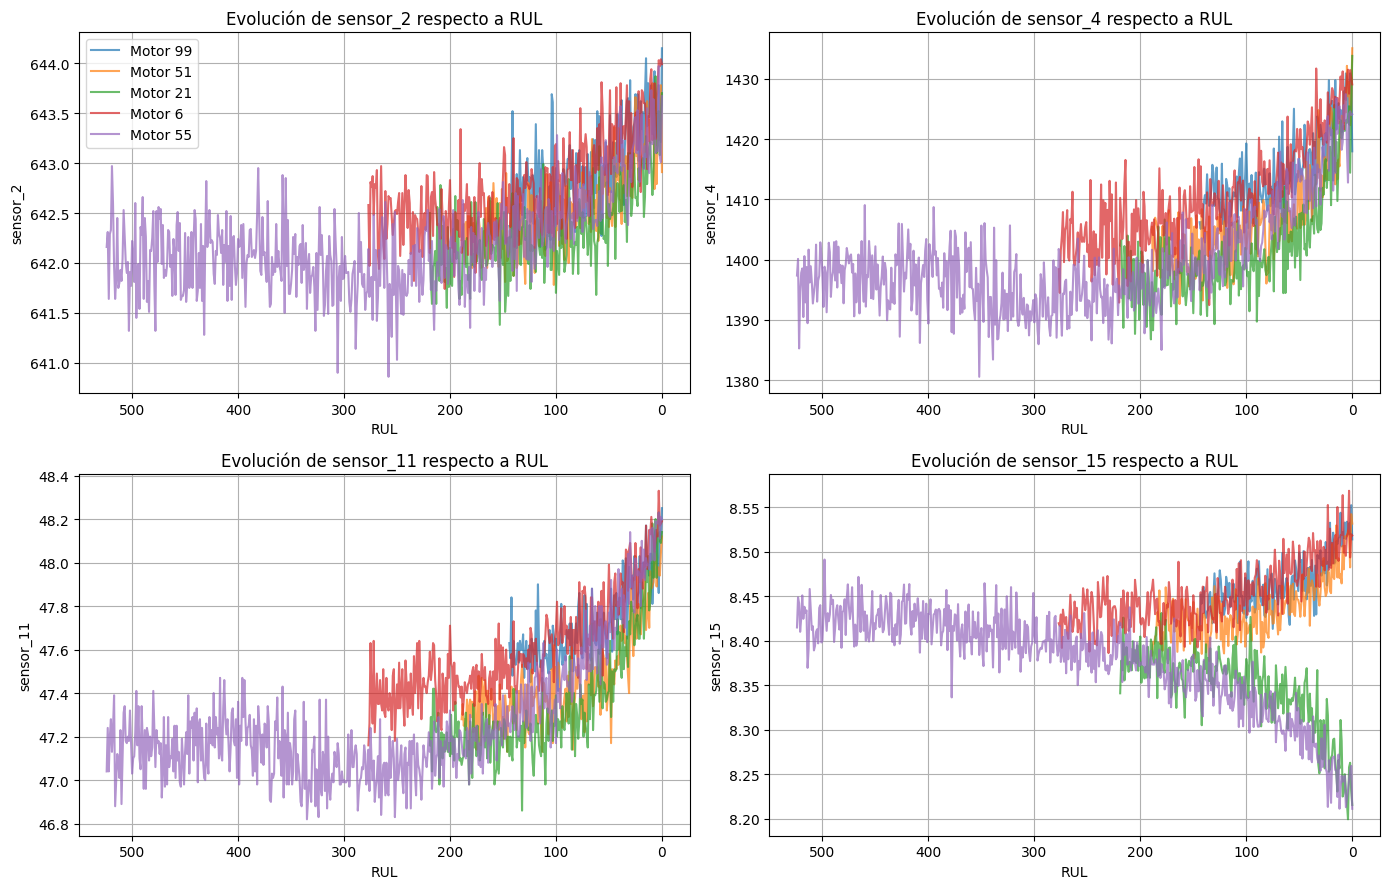

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, sensor in zip(axes.flatten(), sensores_analisis):

    for motor in motores_FD003:
        datos_motor = df_FD003[df_FD003["unit"] == motor]

        ax.plot(
            datos_motor["RUL"],
            datos_motor[sensor],
            label=f"Motor {motor}",
            alpha=0.7
        )

    ax.set_xlabel("RUL")
    ax.set_ylabel(sensor)
    ax.set_title(f"Evolución de {sensor} respecto a RUL")
    ax.invert_xaxis()
    ax.grid(True)

axes[0, 0].legend()

plt.tight_layout()
plt.show()

El análisis conjunto de los cuatro sensores muestra que FD003 presenta patrones de evolución relacionados con la proximidad al final de vida, aunque existen diferencias entre las trayectorias de los motores seleccionados.

Los sensores `sensor_2`, `sensor_4` y `sensor_11` muestran, en términos generales, una tendencia ascendente conforme disminuye la RUL, aunque con fluctuaciones y diferencias entre motores.

En cambio, el `sensor_15` presenta un comportamiento más heterogéneo. Mientras que algunos motores muestran una tendencia creciente al aproximarse al final de vida, otros presentan una tendencia decreciente. Esto pone de manifiesto
que la evolución de determinados sensores no es uniforme entre todas las trayectorias analizadas.

Por su parte, el motor 55, correspondiente a la trayectoria de mayor duración, presenta una región inicial prolongada con valores relativamente estables antes de mostrar cambios más pronunciados conforme se aproxima al final de vida. No obstante, estas representaciones no permiten determinar el momento exacto en que comienza la degradación.

Aunque se observan diferencias entre motores, estas no permiten identificar visualmente de forma fiable los dos mecanismos de degradación presentes en FD003. Por tanto, no sería adecuado asociar las tendencias observadas directamente a degradación del HPC o del Fan sin disponer de etiquetas que permitan comprobarlo.

En conjunto, este análisis muestra que los futuros modelos de prognosis deberán considerar la heterogeneidad de las trayectorias de FD003. La capacidad de los modelos para estimar la RUL en estas condiciones deberá comprobarse posteriormente mediante su evaluación sobre motores no utilizados durante el entrenamiento.

### 1.6. Análisis de FD004

FD004 constituye el escenario más complejo de los cuatro subconjuntos de C-MAPSS, ya que combina **seis condiciones operativas** con **dos modos de degradación asociados al HPC y al Fan**.

Las principales características introducidas por este subconjunto ya se han estudiado por separado en FD002 y FD003. Por este motivo, no se repetirá el análisis completo, sino que se estudiará cómo se manifiesta la diversidad operativa en FD004, teniendo en cuenta que este escenario también incorpora múltiples mecanismos de degradación.

En particular, se analizará la presencia de los diferentes regímenes operativos y su relación con el comportamiento de los sensores.

#### 1.6.1. Condiciones operativas en FD004

En primer lugar, se analizará la distribución conjunta de `op_setting_1` y `op_setting_2` para comprobar la presencia de los seis regímenes operativos en FD004 y compararla con la observada previamente en FD002.

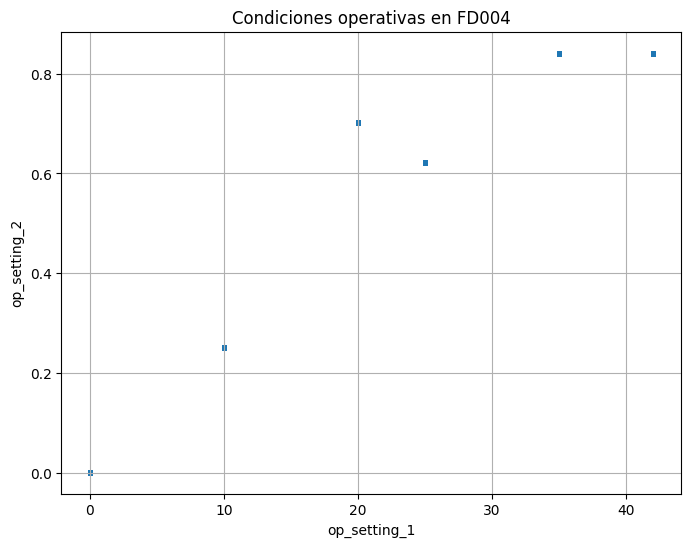

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_FD004["op_setting_1"],
    df_FD004["op_setting_2"],
    s=5,
    alpha=0.3
)

plt.xlabel("op_setting_1")
plt.ylabel("op_setting_2")
plt.title("Condiciones operativas en FD004")
plt.grid(True)
plt.show()

La representación conjunta de `op_setting_1` y `op_setting_2` muestra seis grupos claramente diferenciados, correspondientes a las seis condiciones operativas presentes en FD004.

La distribución observada es muy similar a la obtenida previamente en FD002, lo que confirma que ambos subconjuntos comparten una estructura de múltiples regímenes de funcionamiento.

Por tanto, al igual que en FD002, el análisis de los sensores de FD004 deberá considerar el efecto de las condiciones operativas, ya que parte de la variabilidad de las señales puede estar asociada a cambios en el régimen de funcionamiento y no únicamente al proceso de degradación.

#### 1.6.2. Efecto de las condiciones operativas sobre los sensores

Una vez identificados los seis regímenes operativos de FD004, se analizará su relación con el comportamiento de `sensor_2` para comprobar si las condiciones de funcionamiento influyen en los niveles registrados por el sensor.

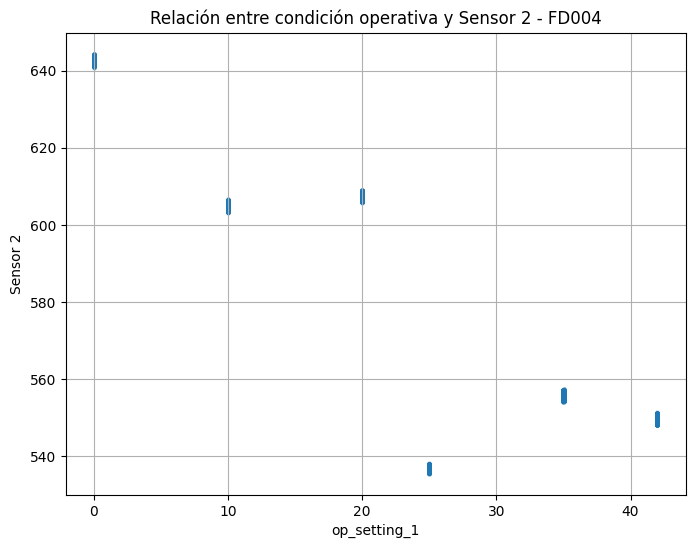

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_FD004["op_setting_1"],
    df_FD004["sensor_2"],
    s=5,
    alpha=0.3
)

plt.xlabel("op_setting_1")
plt.ylabel("Sensor 2")
plt.title("Relación entre condición operativa y Sensor 2 - FD004")
plt.grid(True)
plt.show()

La relación entre `op_setting_1` y `sensor_2` muestra seis grupos claramente diferenciados, asociados a los distintos regímenes de funcionamiento presentes en FD004.

El nivel del sensor cambia considerablemente entre unas condiciones operativas y otras, reproduciendo un comportamiento muy similar al observado previamente en FD002. Esto confirma que una parte importante de la variabilidad del `sensor_2` está asociada al régimen de funcionamiento del motor.

Por tanto, en FD004 no resulta adecuado interpretar directamente las variaciones de los sensores como indicadores de degradación sin considerar previamente las condiciones operativas. Este aspecto será especialmente relevante durante las etapas posteriores de preprocesamiento y modelado.

#### 1.6.3. Evolución temporal de un sensor en FD004

Para observar cómo se refleja la variabilidad asociada a las condiciones operativas a lo largo de una trayectoria individual, se analizará la evolución temporal de `sensor_2` para el motor 1 de FD004.

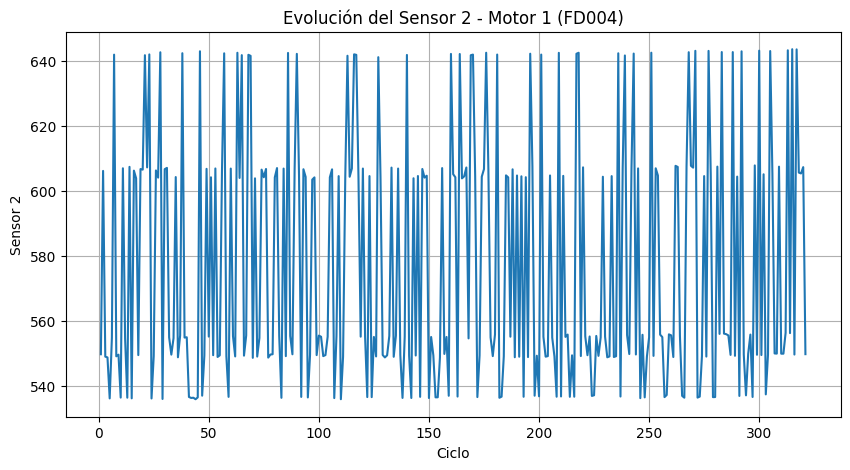

In [ ]:
motor_1_FD004 = df_FD004[df_FD004["unit"] == 1]

plt.figure(figsize=(10, 5))

plt.plot(
    motor_1_FD004["cycle"],
    motor_1_FD004["sensor_2"]
)

plt.xlabel("Ciclo")
plt.ylabel("Sensor 2")
plt.title("Evolución del Sensor 2 - Motor 1 (FD004)")
plt.grid(True)
plt.show()

La evolución temporal del `sensor_2` para el motor 1 de FD004 presenta numerosos cambios bruscos entre diferentes niveles a lo largo de su trayectoria.

Este comportamiento es coherente con el observado previamente al relacionar el sensor con las condiciones operativas, donde se comprobó que cada régimen de funcionamiento está asociado a niveles distintos de la señal.

Por tanto, la evolución temporal del sensor está condicionada por los cambios en el régimen de funcionamiento, dificultando la identificación visual de una tendencia de degradación a partir de la señal sin procesar.

Al igual que en FD002, será necesario considerar las condiciones operativas durante el preprocesamiento y modelado para diferenciar la variabilidad asociada al funcionamiento del motor de aquella relacionada con su degradación.

#### 1.6.4. Conclusiones del análisis de FD004

FD004 combina las principales dificultades identificadas por separado en FD002 y FD003. Por una parte, presenta seis condiciones operativas que afectan a los valores registrados por los sensores. Por otra, incorpora dos modos de degradación, aunque los archivos estándar no proporcionan una etiqueta explícita que permita identificar el modo de fallo correspondiente a cada motor.

Esto convierte a FD004 en el escenario más complejo de los cuatro subconjuntos analizados, ya que los modelos deberán considerar simultáneamente la variabilidad introducida por las condiciones de funcionamiento y la heterogeneidad asociada a diferentes procesos de degradación.

Por este motivo, FD004 resulta especialmente interesante para evaluar posteriormente la capacidad de generalización de los modelos de prognosis en un escenario más complejo.

## 2. Comparación global de los subconjuntos C-MAPSS

El análisis realizado permite identificar diferencias importantes entre los cuatro subconjuntos de C-MAPSS. Aunque todos presentan la misma estructura de variables, la combinación de condiciones operativas y modos de degradación modifica considerablemente la complejidad del problema.

| Dataset | Condiciones operativas | Modos de degradación | Características principales |
|---|---:|---:|---|
| **FD001** | 1 | 1 | Escenario más sencillo. Permite observar con mayor claridad la evolución de los sensores asociada a la degradación. |
| **FD002** | 6 | 1 | Los cambios de régimen operativo producen variaciones importantes en los sensores y dificultan la identificación directa de la degradación. |
| **FD003** | 1 | 2 | Presenta trayectorias de diferente duración y distintos patrones de evolución de los sensores en un escenario con múltiples modos de degradación. |
| **FD004** | 6 | 2 | Combina múltiples condiciones operativas y múltiples modos de degradación, constituyendo el escenario más complejo de los cuatro subconjuntos. |

FD001 proporciona el escenario más sencillo para comenzar el desarrollo de los modelos, ya que presenta una única condición operativa y un único modo de degradación.

La comparación con FD002 ha permitido comprobar que las condiciones operativas tienen una influencia considerable sobre los valores registrados por los sensores. En los escenarios con múltiples condiciones de funcionamiento será necesario tener en cuenta este efecto durante el preprocesamiento y modelado.

FD003 introduce múltiples modos de degradación y presenta una mayor heterogeneidad entre las trayectorias analizadas. Sin embargo, los archivos estándar no contienen una etiqueta explícita que permita asociar cada motor con un modo de fallo concreto, por lo que no puede plantearse directamente una clasificación supervisada HPC/Fan a partir de estos datos.

Finalmente, FD004 combina las dificultades observadas en FD002 y FD003: los sensores están condicionados por diferentes regímenes operativos y el escenario contiene múltiples modos de degradación. Por ello, representa un escenario de mayor complejidad para evaluar posteriormente los modelos desarrollados.

### 2.1. Implicaciones para el desarrollo del TFM

La comparación de los cuatro subconjuntos permite establecer una estrategia progresiva para las siguientes fases del proyecto.

En primer lugar, **FD001 se utilizará como escenario base para el desarrollo inicial del pipeline**, al presentar una única condición operativa y un único modo de degradación. Esto permitirá abordar inicialmente el preprocesamiento, la detección de degradación y la estimación de RUL en un entorno más controlado.

Posteriormente, los subconjuntos FD002, FD003 y FD004 permitirán estudiar escenarios de mayor complejidad. FD002 permitirá analizar el efecto de múltiples condiciones operativas, mientras que FD003 permitirá evaluar el comportamiento de los modelos ante un escenario con múltiples mecanismos de degradación. FD004 permitirá combinar ambas dificultades y estudiar la capacidad de los modelos para trabajar en un escenario más heterogéneo.

La comparación también ha permitido identificar dos aspectos relevantes para las siguientes fases. Por una parte, en FD002 y FD004 será necesario considerar explícitamente las condiciones operativas durante el tratamiento de los sensores. Por otra, la ausencia de etiquetas explícitas de tipo de fallo en FD003 y FD004 limita la posibilidad de plantear directamente una clasificación supervisada HPC/Fan utilizando únicamente los archivos estándar del dataset.

Por tanto, el desarrollo de los modelos comenzará sobre FD001 y posteriormente se estudiará su extensión y evaluación sobre los subconjuntos de mayor complejidad.

### 2.2. Conclusiones

El análisis comparativo de los cuatro subconjuntos C-MAPSS ha permitido identificar las principales diferencias relacionadas con las condiciones operativas, los mecanismos de degradación y el comportamiento de las trayectorias temporales.

Los resultados muestran la importancia de considerar las características de cada escenario durante el desarrollo de los modelos de mantenimiento predictivo. En particular, se ha observado una asociación entre las condiciones operativas y los valores del `sensor_2` en FD002 y FD004, así como una mayor heterogeneidad en determinados patrones de evolución de los sensores analizados en FD003.

Además, se ha identificado como limitación la ausencia de etiquetas explícitas que permitan asociar cada motor de FD003 y FD004 con un mecanismo de degradación concreto, lo que condiciona el planteamiento de una clasificación supervisada de tipos de fallo.

Con esta comparación se completa la fase inicial de comprensión del dataset C-MAPSS y se establece una estrategia de desarrollo progresiva. La siguiente etapa consistirá en preparar los datos de FD001 para el entrenamiento de los modelos de detección de anomalías y estimación de RUL, que posteriormente se extenderán a escenarios de mayor complejidad.